# 01 — ML Fundamentals: Paradigms, Parameters vs Hyperparameters, Capacity

**Overview:** one small runnable example per learning paradigm (supervised, unsupervised,
semi-supervised, self-supervised, reinforcement — conceptually), a worked parameters-vs-
hyperparameters example, training vs inference, and an underfit/good-fit/overfit demo.

**Required libraries:** `numpy`, `matplotlib`, `scikit-learn`.

Connects to: Day 1's `05_ml_mathematics` (gradient descent) and `04_datasets` (splits). Leads
to: `07_regression`, where supervised learning gets its first full treatment.

### Abbreviations used in this notebook

| Term | Full form | What it is |
|---|---|---|
| **ML** | Machine Learning | Learning patterns from data to make predictions, instead of hand-coding rules. |
| **RL** | Reinforcement Learning | Agent learns by trial and error from a (possibly delayed) reward signal. |
| **LLM** | Large Language Model | Very large Transformer trained on text to predict the next token (e.g. GPT). |
| **MSE** | Mean Squared Error | Average of squared prediction errors; the standard regression loss. |

## 0. Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.preprocessing import PolynomialFeatures
print("ready")
rng = np.random.default_rng(42)


ready


## 1. Supervised learning

💡 **Intuition:** learn `f(features) -> label` from examples where the label is already
known.

In [ ]:
X = rng.uniform(-3, 3, size=(50, 1))
#print("X shape:", X)
y_true = 2 * X.squeeze() + 1 + rng.normal(scale=0.5, size=50)   # known labels

model = LinearRegression().fit(X, y_true)
print("learned parameters -> coef:", model.coef_, "intercept:", model.intercept_)
print("prediction for X=5:", model.predict([[5.0]]))


X shape: [[ 1.1887247 ]
 [ 2.02788131]
 [-2.7590922 ]
 [-1.78930734]
 [-2.25045792]
 [ 0.02718594]
 [ 1.47112877]
 [ 0.78007107]
 [ 2.1067866 ]
 [-2.06872205]
 [ 1.40772655]
 [-1.84175105]
 [-1.37544749]
 [ 1.25942818]
 [ 2.88122871]
 [ 0.66926164]
 [-2.67299811]
 [ 0.69785382]
 [-2.74589669]
 [ 2.30487427]
 [ 1.25746971]
 [-1.96123292]
 [-2.44967397]
 [-1.89880063]
 [ 2.88016308]
 [-0.24863615]
 [ 1.70448569]
 [ 0.81845005]
 [ 0.4344789 ]
 [-2.12921847]
 [ 2.67614672]
 [-1.1919442 ]
 [ 0.46810329]
 [ 1.19865567]
 [ 0.89539893]
 [ 2.64356646]
 [-2.10936606]
 [ 0.05011643]
 [-0.57579366]
 [-0.15498762]
 [-2.28469484]
 [-2.19543234]
 [-1.33154673]
 [-1.17177238]
 [-0.43258072]
 [ 0.66592528]
 [ 0.8077747 ]
 [-0.52913462]
 [-0.54730134]
 [-1.69422884]]
learned parameters -> coef: [1.96654955] intercept: 0.9600302722436442
prediction for X=5: [10.79277803]


## 2. Unsupervised learning

💡 **Intuition:** find structure (e.g. clusters) with no labels at all.

cluster assignments (first 10): [1 1 1 1 1 1 1 1 1 1]
learned cluster centers (parameters):
 [[ 5.00290585e+00  5.01074954e+00]
 [-2.54117423e-02 -3.45094464e-02]
 [-2.48448429e-03  4.96620485e+00]]
hyperparameter n_clusters was set to 3 BEFORE fitting -- it is not learned from data.


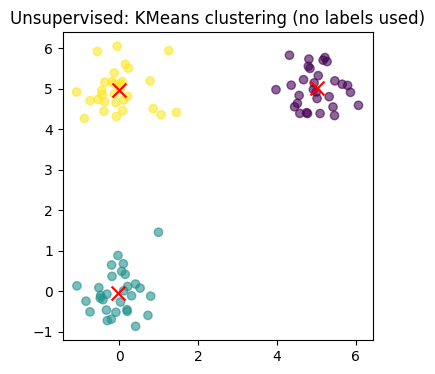

In [3]:
cluster_data = np.concatenate([
    rng.normal(loc=[0, 0], scale=0.5, size=(30, 2)),
    rng.normal(loc=[5, 5], scale=0.5, size=(30, 2)),
    rng.normal(loc=[0, 5], scale=0.5, size=(30, 2)),
])
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(cluster_data)
print("cluster assignments (first 10):", kmeans.labels_[:10])
print("learned cluster centers (parameters):\n", kmeans.cluster_centers_)
print("hyperparameter n_clusters was set to 3 BEFORE fitting -- it is not learned from data.")

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(cluster_data[:, 0], cluster_data[:, 1], c=kmeans.labels_, cmap="viridis", alpha=0.6)
ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="red", marker="x", s=100)
ax.set_title("Unsupervised: KMeans clustering (no labels used)")
plt.show()


## 3. Semi-supervised and self-supervised learning (concept + tiny demo)

💡 **Intuition:** semi-supervised = a few labels + lots of unlabeled data. Self-supervised =
labels are derived automatically from the data itself (e.g. "predict the masked value from its
neighbors") — this is how large language models are pretrained, on raw text with no human
labels at all.

In [4]:
# Self-supervised toy task: given a short sequence, mask one element and predict it from its
# neighbors -- the "label" (the masked value) came from the data itself, not a human annotator.
sequence = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0])

def make_self_supervised_examples(seq):
    features, labels = [], []
    for i in range(1, len(seq) - 1):
        features.append([seq[i - 1], seq[i + 1]])   # neighbors as features
        labels.append(seq[i])                        # the masked value as the "label"
    return np.array(features), np.array(labels)

X_self, y_self = make_self_supervised_examples(sequence)
self_model = LinearRegression().fit(X_self, y_self)
print("self-supervised features (neighbor pairs):\n", X_self)
print("self-supervised labels (masked values, derived from the data itself):", y_self)
print("learned to predict the masked value as roughly the average of its neighbors:",
      self_model.coef_.round(2))


self-supervised features (neighbor pairs):
 [[1. 3.]
 [2. 4.]
 [3. 5.]
 [4. 6.]
 [5. 7.]
 [6. 8.]]
self-supervised labels (masked values, derived from the data itself): [2. 3. 4. 5. 6. 7.]
learned to predict the masked value as roughly the average of its neighbors: [0.5 0.5]


## 4. Reinforcement learning (concept)

💡 **Intuition:** no fixed labeled dataset at all -- an agent takes actions in an environment and
learns from a reward signal, which may be delayed. A full RL demo needs an environment and is
out of scope here (covered conceptually; hands-on RL comes with Day 3's `04_preference_optimization_rl`
-style content in the LLM fine-tuning curriculum). The point for now: RL's training signal
(reward) is fundamentally different from supervised learning's fixed labels.

## 5. Training vs inference

🎯 **Interview Tip:** training is the only phase that touches the loss function and the
optimizer; inference is a pure forward pass through already-fixed parameters.

In [5]:
# TRAINING: parameters (coef_, intercept_) get updated by minimizing a loss on labeled data.
train_model = LinearRegression().fit(X, y_true)
print("after training, parameters are fixed:", train_model.coef_, train_model.intercept_)

# INFERENCE: no fitting, no loss, no optimizer -- just applying the fixed parameters.
new_inputs = np.array([[0.0], [1.0], [2.0]])
predictions = train_model.predict(new_inputs)
print("inference predictions on new, unseen inputs:", predictions)


after training, parameters are fixed: [2.01006334] 0.9145194935597116
inference predictions on new, unseen inputs: [0.91451949 2.92458284 4.93464618]


## 6. Model capacity and generalization: underfit vs good-fit vs overfit

⚠️ **Common Mistake:** judging a model only by training error. Below, the degree-15 polynomial
has the LOWEST training error but is clearly the worst at generalizing.

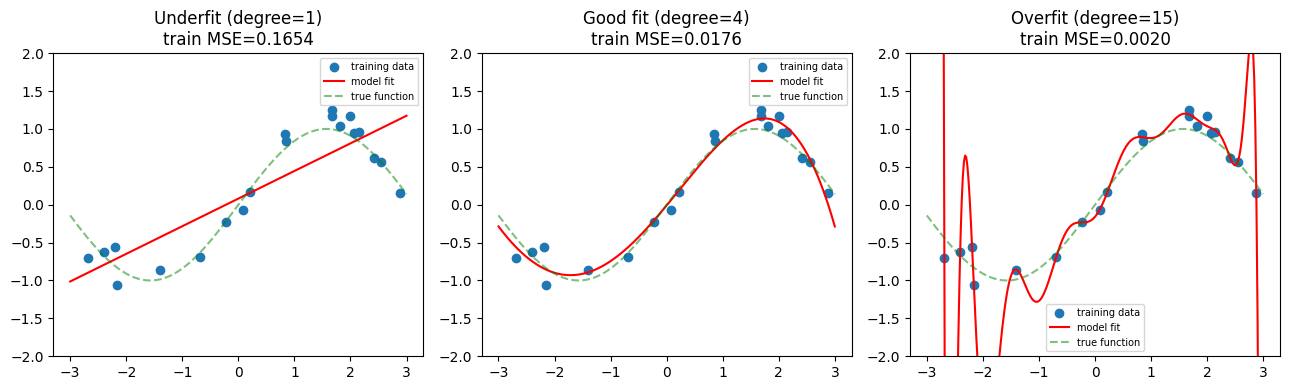

Capacity increases left-to-right (more polynomial terms = more flexible function class).
The degree=15 model will show the LOWEST train MSE but visibly oscillates wildly between points -- it is memorizing noise, not the underlying sin() pattern, and would generalize worst to new x-values.


In [6]:
n_points = 20
X_small = np.sort(rng.uniform(-3, 3, size=(n_points, 1)), axis=0)
y_small = np.sin(X_small).squeeze() + rng.normal(scale=0.15, size=n_points)
X_dense = np.linspace(-3, 3, 300).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, degree, title in zip(axes, [1, 4, 15], ["Underfit (degree=1)", "Good fit (degree=4)", "Overfit (degree=15)"]):
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X_small)
    model = LinearRegression().fit(X_poly, y_small)
    y_dense_pred = model.predict(poly.transform(X_dense))
    train_pred = model.predict(X_poly)
    train_mse = np.mean((train_pred - y_small) ** 2)

    ax.scatter(X_small, y_small, label="training data")
    ax.plot(X_dense, y_dense_pred, color="red", label="model fit")
    ax.plot(X_dense, np.sin(X_dense), color="green", linestyle="--", alpha=0.5, label="true function")
    ax.set_title(f"{title}\ntrain MSE={train_mse:.4f}")
    ax.set_ylim(-2, 2)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

print("Capacity increases left-to-right (more polynomial terms = more flexible function class).")
print("The degree=15 model will show the LOWEST train MSE but visibly oscillates wildly between "
      "points -- it is memorizing noise, not the underlying sin() pattern, and would generalize "
      "worst to new x-values.")


## 7. Connection to what's next

The underfit/good-fit/overfit demo above is `11_generalization`'s entire subject, formalized.
`07_regression` picks up supervised learning next, starting from exactly the `LinearRegression`
call used throughout this notebook.

## 8. Interview questions
1. Name the five learning paradigms covered here and one example of each.
2. For `PolynomialFeatures(degree=15)` fed into `LinearRegression`, what's a parameter and what's a hyperparameter?
3. Why does self-supervised learning not require human-annotated labels, yet still count as "supervised" in the sense of having a target to predict?
4. What computation happens during inference that does NOT happen during training?
5. Why is a model with lower training error not necessarily the better model?

## 9. Exercises
1. Repeat the capacity demo with a different true function (e.g. a step function) and observe how the "good fit" degree changes.
2. List every hyperparameter and every learned parameter for `KMeans(n_clusters=3, random_state=42)`.
3. Design a self-supervised task for 2D grid data (e.g. predict a masked cell from its 4 neighbors) and implement it with `LinearRegression`.

## 10. Summary

✅ Supervised/unsupervised/semi-/self-supervised/reinforcement are different training *signals*;
parameters are learned, hyperparameters are set beforehand; training updates parameters,
inference only applies them; capacity must match the data, or you underfit or overfit. Next:
`07_regression`.